# XFoil vs Neuralfoil 

This notebook experiments about the gap between low-fidelity neuralfoil and high-fidelity (with respect to the project) XFoil on a simple 2D airfoil under normal operating conditions. 


In [28]:
from aerosandbox.aerodynamics.aero_2D.xfoil import XFoil
from aerosandbox import numpy as np 
from aerosandbox.geometry import Airfoil 
from matplotlib import pyplot as plt 

%run ../utils/run_xfoil_patch.py

In [57]:
airfoil = Airfoil("NACA0012", xfoil=True)

grid_res = 50
reynolds = np.linspace(1e6, 2e6, grid_res)
alphas = np.linspace(-10, 10, grid_res)

## aerodynamic sweeps 
aero_nf = airfoil.get_aero_from_neuralfoil(alpha=alphas, Re=1e6, model_size="xlarge")

aero_xf = XFoil(
    airfoil=airfoil,
    Re=1e6,
    # verbose=True,
).alpha(alphas)

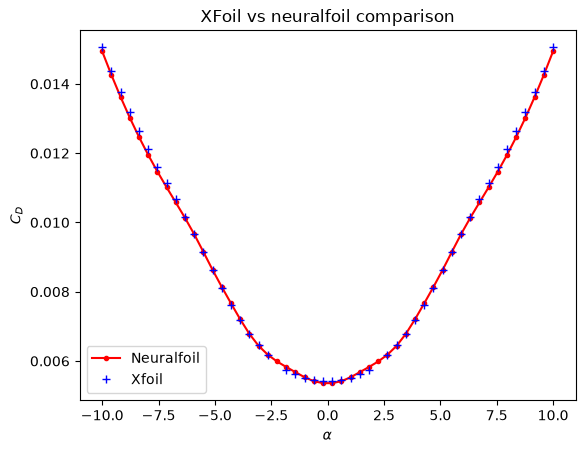

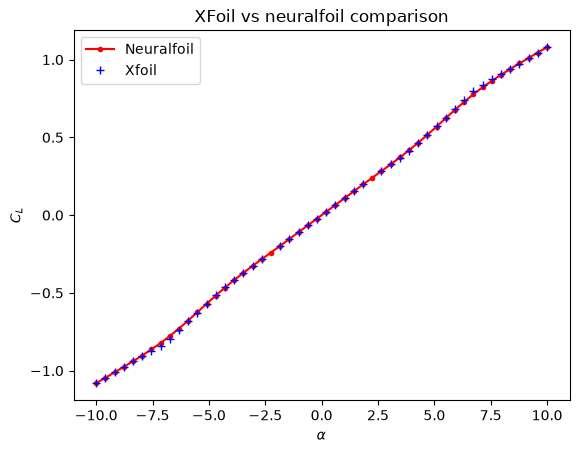

In [62]:
## comparison 

## CD alpha sweep 
plt.plot(alphas, aero_nf["CD"], color="red", label="Neuralfoil", linestyle="-", marker=".")
plt.plot(aero_xf["alpha"], aero_xf["CD"], color="blue", label="Xfoil", linestyle="", marker="+")

plt.xlabel("$\\alpha$")
plt.ylabel("$C_D$")
plt.legend()
plt.title("XFoil vs neuralfoil comparison")
plt.show() 

## CL alpha sweep 
plt.plot(alphas, aero_nf["CL"], color="red", label="Neuralfoil", linestyle="-", marker=".")
plt.plot(aero_xf["alpha"], aero_xf["CL"], color="blue", label="Xfoil", linestyle="", marker="+")

plt.xlabel("$\\alpha$")
plt.ylabel("$C_L$")
plt.legend()
plt.title("XFoil vs neuralfoil comparison")
plt.show()

In [63]:
## Computing aero fields from neuralfoil and xfoil 

a, r = np.meshgrid(alphas, reynolds)

## neuralfoil computation 
aero_nf = airfoil.get_aero_from_neuralfoil(alpha=a.flatten(), Re=r.flatten(), model_size="xlarge")

## xfoil computation 
aero_xf_per_Re = []
for i, re in enumerate(reynolds):
    aero_xf_per_Re.append(
        XFoil(
            airfoil=airfoil,
            Re=re,
            # verbose=True,
        ).alpha(alphas)
    )


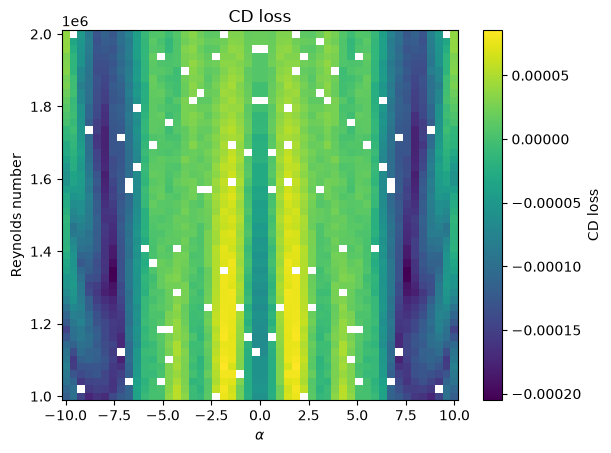

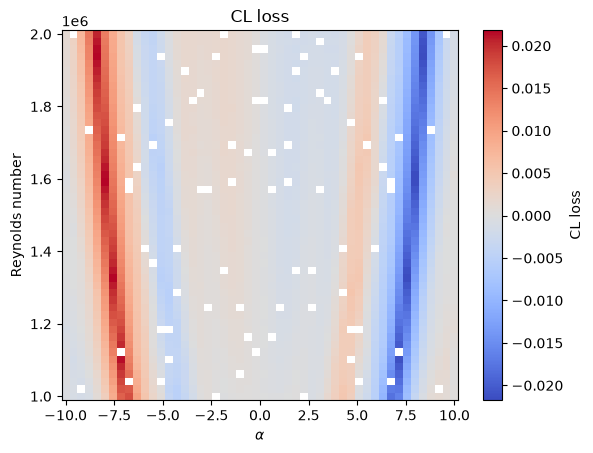

In [65]:
## comparing model accuracy on fields 

nf_CD = aero_nf["CD"].reshape(a.shape)
nf_CL = aero_nf["CL"].reshape(a.shape)

xf_CD = np.full(a.shape, np.nan)
xf_CL = np.full(a.shape, np.nan)

alpha_values = a[0, :]

for i, aero in enumerate(aero_xf_per_Re):
    ## keep only converged alphas 
    returned_alpha = np.asarray(aero["alpha"])
    returned_CD = np.asarray(aero["CD"])
    returned_CL = np.asarray(aero["CL"])

    for alpha, cd, cl in zip(returned_alpha, returned_CD, returned_CL):
        j = np.argmin(np.abs(alpha_values - alpha))
        xf_CD[i, j] = cd
        xf_CL[i, j] = cl

## CD loss
p = plt.pcolormesh(
    a, r, 
    nf_CD - xf_CD,
    cmap="viridis"
)

## colorbar 
cbar = plt.colorbar(p, label="CD loss")
# cbar.set_clim(-0.5, 0.5)

plt.xlabel(r"$\alpha$")
plt.ylabel("Reynolds number")
plt.title("CD loss")
plt.show()

## CL loss 
p = plt.pcolormesh(
    a, r, 
    nf_CL - xf_CL,
    cmap="coolwarm"
)

## colorbar 
cbar = plt.colorbar(p, label="CL loss")
# cbar.set_clim(-0.5, 0.5)

plt.xlabel(r"$\alpha$")
plt.ylabel("Reynolds number")
plt.title("CL loss")
plt.show()

## XFoil vs Neuralfoil comparison on fields 

For a given symmetric airfoil (NACA0006), the loss fields are (coherently) symmetric around angle of attack (anti-symmetric for lift coeff.).

**CD** Neuralfoil (`xlarge` model size) overestimates the $C_D$ in bands angle of attacks appearing around $|\alpha| \leq \approx 6$, above which underestimation appears. The magnitude orders of imprecision on $C_D$ do not exceed around 2e-4 in absolute value. 

**CL** Major losses appear at angle of attacks of around 7.5. Orders of magnitude reach at most 0.2 in absolute values. 